# Países do mundo: exploratory analysis

Quick tour of `data/paises.parquet`: coverage, languages, currencies and locale formats. Run from the repository root or from `notebooks/`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
df = pd.read_parquet(root / 'data' / 'paises.parquet')
print(df.shape)
df.head(3).T.head(20)

(167, 53)


,0,1,2
iso2,AL,DE,AO
iso3,ALB,DEU,AGO
iso_numeric,008,276,024
ioc_code,ALB,GER,ANG
name_en,Albania,Germany,Angola
name_pt,Albânia,Alemanha,Angola
official_name_pt,República da Albânia,República Federal da Alemanha,República de Angola
official_name_en,Republic of Albania,Federal Republic of Germany,Republic of Angola
native_name,Shqipëria,Deutschland,Angola
flag_emoji,🇦🇱,🇩🇪,🇦🇴


## Coverage by UN region

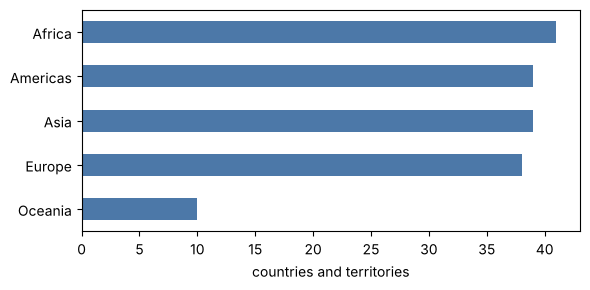

In [2]:
ax = df['un_region'].value_counts().sort_values().plot.barh(color='#4C78A8', figsize=(6, 3))
ax.set_xlabel('countries and territories')
ax.set_ylabel('')
plt.tight_layout()

## Main languages

How many countries use each main language, and how many people that represents (approximate).

In [3]:
lang = (df.groupby('primary_language')
          .agg(countries=('iso2', 'size'), population_millions=('population_millions', 'sum'))
          .sort_values('countries', ascending=False))
lang.head(12).round(1)

,countries,population_millions
primary_language,,
en,52,1193.4
es,18,465.0
ar,16,390.0
fr,12,378.6
pt,7,298.0
zh,4,1440.5
de,3,102.7
nl,3,30.4
ru,3,172.6


## Currencies shared by several countries

In [4]:
currencies = df.assign(code=df['currency_codes'].str.split('|')).explode('code')
currencies.groupby('code')['name_pt'].agg(['size', lambda s: ', '.join(sorted(s)[:6])]).rename(columns={'size': 'countries', '<lambda_0>': 'examples'}).sort_values('countries', ascending=False).head(8)

,countries,examples
code,,
EUR,21,"Alemanha, Bulgária, Bélgica, Chipre, Croácia, ..."
USD,9,"El Salvador, Equador, Estados Unidos, Ilhas Tu..."
XCD,8,"Anguila, Antígua e Barbuda, Dominica, Granada,..."
XOF,7,"Benin, Burkina Faso, Costa do Marfim, Guiné-Bi..."
XAF,4,"Camarões, Chade, Congo, Gabão"
AUD,2,"Austrália, Nauru"
ZAR,2,"Namíbia, África do Sul"
AZN,1,Azerbaijão


## Locale formats

The decisions a localisation layer has to make, country by country.

In [5]:
for column in ['decimal_separator', 'grouping_separator', 'first_day_of_week', 'time_format', 'driving_side', 'paper_size']:
    print(column.ljust(20), df[column].value_counts().to_dict())

decimal_separator    {'period': 86, 'comma': 81}
grouping_separator   {'comma': 85, 'period': 39, 'space': 30, 'narrow_space': 12, 'apostrophe': 1}
first_day_of_week    {'monday': 110, 'sunday': 48, 'saturday': 9}
time_format          {'24h': 86, '12h': 81}
driving_side         {'right': 114, 'left': 53}
paper_size           {'A4': 154, 'Letter': 13}


## Right-to-left and multi-zone countries

In [6]:
print('RTL main language:', ', '.join(df.loc[df['writing_direction'] == 'rtl', 'name_pt']))
print()
df.nlargest(8, 'utc_offset_count')[['name_pt', 'utc_offset_count', 'utc_offsets']]

RTL main language: Arábia Saudita, Argélia, Bahrein, Catar, Egito, Emirados Árabes Unidos, Iêmen, Iraque, Israel, Jordânia, Kuwait, Líbano, Líbia, Marrocos, Mauritânia, Omã, Paquistão, Tunísia



,name_pt,utc_offset_count,utc_offsets
136,Rússia,11,UTC+02:00 a UTC+12:00
31,Canadá,6,UTC-08:00 a UTC-03:30
54,Estados Unidos,6,UTC-10:00 a UTC-05:00
9,Austrália,5,UTC+08:00 a UTC+10:30
24,Brasil,4,UTC-05:00 a UTC-02:00
105,México,4,UTC-08:00 a UTC-05:00
35,Chile,3,UTC-06:00 a UTC-03:00
77,Indonésia,3,UTC+07:00 a UTC+09:00


## Portuguese-speaking countries (CPLP members in the dataset)

In [7]:
df[df['primary_language'] == 'pt'][['flag_emoji', 'name_pt', 'capital_en', 'currency_codes', 'calling_code', 'locale', 'short_date_pattern']]

,flag_emoji,name_pt,capital_en,currency_codes,calling_code,locale,short_date_pattern
2,🇦🇴,Angola,Luanda,AOA,+244,pt-AO,dd/MM/yy
24,🇧🇷,Brasil,Brasília,BRL,+55,pt-BR,dd/MM/y
28,🇨🇻,Cabo Verde,Praia,CVE,+238,pt-CV,dd/MM/yy
68,🇬🇼,Guiné-Bissau,Bissau,XOF,+245,pt-GW,dd/MM/yy
107,🇲🇿,Moçambique,Maputo,MZN,+258,pt-MZ,dd/MM/yy
128,🇵🇹,Portugal,Lisbon,EUR,+351,pt-PT,dd/MM/yy
139,🇸🇹,São Tomé e Príncipe,São Tomé,STN,+239,pt-ST,dd/MM/yy


## Largest countries by area, with density

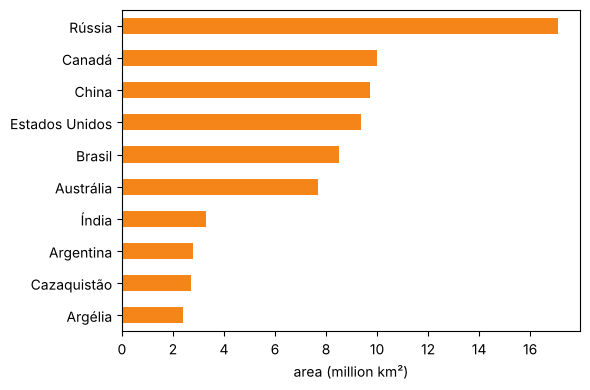

In [8]:
top = df.nlargest(10, 'area_km2').set_index('name_pt')
ax = top['area_km2'].div(1e6).sort_values().plot.barh(color='#F58518', figsize=(6, 4))
ax.set_xlabel('area (million km²)')
ax.set_ylabel('')
plt.tight_layout()